# Court Document Classification: Doc2Vec and Model Comparison

This notebook compares several classifiers on **Doc2Vec** document embeddings and computes Accuracy, Precision, Recall, F1, ROC-AUC and a confusion matrix.

**Expected data:** `df2.csv` in the same folder, columns `text` and `class`, separator `;`, encoding `windows-1251`. `df2.csv` was got after "pdf_corpus_to_csv.R" script completing, search for pdf-documents on https://ras.arbitr.ru/

**Speed and memory optimizations compared with the previous version**
- Stemming results are cached (`lru_cache`): the stemmer is called once per unique word instead of once per token occurrence, which is the main saving in preprocessing.
- Doc2Vec uses integer document tags, so train vectors are read straight from `doc2vec.dv.vectors` (no per-document dictionary lookups).
- Test vectors (`infer_vector`) are computed in a small thread pool instead of a single-threaded loop.
- Linear models (Logistic Regression, Linear SVM) use standardized features, which makes them converge much faster; `LinearSVC` uses `dual=False`, the fast mode when there are more samples than features.
- ROC-AUC is computed with one vectorised call and also works for models that only have `decision_function` (such as Linear SVM), which previously produced `NaN`.
- Core usage is capped (`N_JOBS`, `INFER_THREADS`) so that parallel workers do not exhaust RAM; unused imports are removed.

## 1. Imports and settings

In [1]:
import os
import time
import warnings
from concurrent.futures import ThreadPoolExecutor
from functools import lru_cache
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from gensim.models.doc2vec import Doc2Vec, TaggedDocument
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

RANDOM_STATE = 42
TEST_SIZE = 0.25
DOC2VEC_VECTOR_SIZE = 100
DOC2VEC_WINDOW = 5
DOC2VEC_MIN_COUNT = 2
DOC2VEC_EPOCHS = 30
INFER_EPOCHS = 20
MAX_CLASSES_IN_PLOT = 25

CPU_COUNT = os.cpu_count() or 1
DOC2VEC_WORKERS = max(1, min(CPU_COUNT, 8))  # gensim gains little beyond ~8 workers
N_JOBS = 4            # cores for Random Forest / LightGBM (-1 = all; lower it if RAM is tight)
INFER_THREADS = 4     # threads for infer_vector on the test set (1 = exactly reproducible vectors)

# LightGBM is optional: if installed, it is added to the comparison.
try:
    from lightgbm import LGBMClassifier
    HAS_LIGHTGBM = True
except ImportError:
    HAS_LIGHTGBM = False
    print("LightGBM is not installed - the model will be skipped.")

## 2. Loading and checking the data

In [2]:
DATA_PATH = Path("df2.csv")
# dtype=str avoids slow mixed-type inference
docs = pd.read_csv(DATA_PATH, sep=";", encoding="windows-1251", dtype=str)

required_columns = {"text", "class"}
missing = required_columns - set(docs.columns)
if missing:
    raise ValueError(f"Required columns are missing from the dataset: {missing}")

print("Original dataset shape:", docs.shape)
print("Number of classes:", docs["class"].nunique())
print("Empty texts:", docs["text"].isna().sum())
print("Empty labels:", docs["class"].isna().sum())

docs = docs[["text", "class"]].dropna().copy()
docs["text"] = docs["text"].str.strip()
docs = docs[docs["text"].ne("")].copy()
docs["class"] = docs["class"].str.strip()
docs = docs.reset_index(drop=True)

class_counts = docs["class"].value_counts()
display(class_counts.to_frame("documents").head(30))
print("Minimum documents per class:", class_counts.min())

Original dataset shape: (28413, 3)
Number of classes: 15
Empty texts: 0
Empty labels: 0


,documents
class,
12,1986
3,1976
13,1968
9,1955
8,1947
14,1947
7,1941
11,1936
4,1933


Minimum documents per class: 1645


## 3. Text preprocessing

For Doc2Vec we use space-separated tokens. Stop words and the stemmer are created once rather than for every document, and stemming results are cached per unique word. This keeps the overall approach of the original notebook but removes a lot of repeated work.

In [3]:
import re
from nltk.corpus import stopwords
from nltk.stem.snowball import SnowballStemmer
import nltk

try:
    STOP_WORDS = set(stopwords.words("russian"))
except LookupError:
    nltk.download("stopwords")
    STOP_WORDS = set(stopwords.words("russian"))

STEMMER = SnowballStemmer("russian")
stem = lru_cache(maxsize=None)(STEMMER.stem)   # each unique word is stemmed only once
TOKEN_PATTERN = re.compile(r"\w+", flags=re.UNICODE)

def process_text(text):
    tokens = TOKEN_PATTERN.findall(text.lower())
    return [
        stem(token)
        for token in tokens
        if len(token) > 1 and token not in STOP_WORDS
    ]

start = time.perf_counter()
docs["tokens"] = docs["text"].map(process_text)
docs = docs[docs["tokens"].map(bool)].reset_index(drop=True)
print(f"Preprocessing: {time.perf_counter() - start:.1f} s")
print("Unique stemmed words cached:", stem.cache_info().currsize)
print("Documents after cleaning:", len(docs))
docs[["class", "tokens"]].head()

Preprocessing: 113.7 s
Unique stemmed words cached: 503031
Documents after cleaning: 28413


,class,tokens
0,1,"[арбитражн, суд, республик, адыге, имен, росси..."
1,1,"[арбитражн, суд, республик, адыге, имен, росси..."
2,1,"[арбитражн, суд, республик, адыге, имен, росси..."
3,1,"[арбитражн, суд, республик, адыге, имен, росси..."
4,1,"[арбитражн, суд, республик, адыге, имен, росси..."


## 4. Train/test split

Stratification helps preserve the class distribution in both sets. It requires at least two documents in every class. If this condition is not met, decide first how to handle extremely rare classes.

In [4]:
class_counts = docs["class"].value_counts()
rare_classes = class_counts[class_counts < 2]
if len(rare_classes):
    print(f"Warning: {len(rare_classes)} classes have fewer than 2 documents; they will be excluded from this experiment.")
    docs = docs[~docs["class"].isin(rare_classes.index)].reset_index(drop=True)

train, test = train_test_split(
    docs,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=docs["class"],
)
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)

y_train = train["class"].to_numpy()
y_test = test["class"].to_numpy()
print(f"Train: {len(train):,}; test: {len(test):,}; classes: {docs['class'].nunique():,}")

Train: 21,309; test: 7,104; classes: 15


## 5. Training Doc2Vec

**Important:** every document must have its own unique tag. The class label must not be used as a document tag: otherwise all documents of one class would share a single trainable representation. Here the tag is simply the document's row number in the train set.

In [5]:
train_tagged = [
    TaggedDocument(words=tokens, tags=[i])     # integer tag = row index in train
    for i, tokens in enumerate(train["tokens"])
]

doc2vec = Doc2Vec(
    vector_size=DOC2VEC_VECTOR_SIZE,
    window=DOC2VEC_WINDOW,
    min_count=DOC2VEC_MIN_COUNT,
    dm=0,                 # DBOW
    sample=1e-5,
    workers=DOC2VEC_WORKERS,
    seed=RANDOM_STATE,
    epochs=DOC2VEC_EPOCHS,
)

start = time.perf_counter()
doc2vec.build_vocab(train_tagged)
doc2vec.train(
    train_tagged,
    total_examples=doc2vec.corpus_count,
    epochs=DOC2VEC_EPOCHS,
)
print(f"Doc2Vec training: {time.perf_counter() - start:.1f} s")

# For train we use the learned document vectors (integer tags -> row i of the matrix).
n_train = len(train_tagged)
X_train = np.array(doc2vec.dv.vectors[:n_train], dtype=np.float32)
assert X_train.shape[0] == n_train

# For test we use infer_vector; test texts do not take part in Doc2Vec training.
def infer(tokens):
    return doc2vec.infer_vector(tokens, epochs=INFER_EPOCHS)

start = time.perf_counter()
with ThreadPoolExecutor(max_workers=INFER_THREADS) as pool:
    X_test = np.array(list(pool.map(infer, test["tokens"])), dtype=np.float32)
print(f"Computing test vectors: {time.perf_counter() - start:.1f} s")
print("X_train:", X_train.shape, "X_test:", X_test.shape)

# Standardized copy for linear models (scaler is fitted on train only)
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

doc2vec.save("model.doc2vec")

Doc2Vec training: 564.2 s
Computing test vectors: 180.6 s
X_train: (21309, 100) X_test: (7104, 100)


## 6. Classifiers to compare

All models receive the same Doc2Vec vectors and the same train/test split. Linear models use the standardized copy of the vectors (faster convergence); the other models use the raw vectors. For a first comparison the parameters are mostly kept close to the defaults; after a baseline run they can be tuned.

In [6]:
# Each entry: name -> (estimator, feature set: "raw" or "scaled")
models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), "scaled"),
    "Linear SVM": (LinearSVC(dual=False, random_state=RANDOM_STATE), "scaled"),
    "Gaussian Naive Bayes": (GaussianNB(), "raw"),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), "raw"),
    "Random Forest": (RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=N_JOBS
    ), "raw"),
    "AdaBoost": (AdaBoostClassifier(n_estimators=100, random_state=RANDOM_STATE), "raw"),
}

if HAS_LIGHTGBM:
    models["LightGBM"] = (LGBMClassifier(
        objective="multiclass",
        n_estimators=200,
        random_state=RANDOM_STATE,
        verbosity=-1,
        n_jobs=N_JOBS,
    ), "raw")

features = {
    "raw": (X_train, X_test),
    "scaled": (X_train_scaled, X_test_scaled),
}

print("Models:", ", ".join(models))

Models: Logistic Regression, Linear SVM, Gaussian Naive Bayes, Decision Tree, Random Forest, AdaBoost, LightGBM


## 7. Metrics, ROC-AUC and per-class report

For a multiclass problem, ROC-AUC is computed One-vs-Rest with macro averaging. ROC-AUC needs confidence scores: `predict_proba` or `decision_function`. If a particular model/split does not allow a correct ROC-AUC, the table shows `NaN` and the reason appears in the output.

Macro F1 weights all classes equally, Weighted F1 accounts for the size of each class.

In [7]:
def get_score_matrix(model, X):
    """Return class scores for ROC-AUC if the model supports them."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)
    if hasattr(model, "decision_function"):
        return model.decision_function(X)
    return None

def macro_ovr_auc(model, X, y_true):
    """Macro one-vs-rest ROC-AUC in one vectorised call (works with probabilities and decision scores)."""
    score = get_score_matrix(model, X)
    if score is None:
        raise ValueError("The model provides neither predict_proba nor decision_function")
    score = np.asarray(score)
    classes = list(model.classes_)
    y_bin = label_binarize(y_true, classes=classes)
    if len(classes) == 2:
        # Binary case: use the score of the positive (second) class
        score = score[:, 1] if score.ndim == 2 else score
        return float(roc_auc_score(y_bin.ravel(), score))
    return float(roc_auc_score(y_bin, score, average="macro"))

results = []
reports = {}
predictions = {}
trained_models = {}

for name, (model, feature_set) in models.items():
    Xtr, Xte = features[feature_set]
    print(f"\n===== {name} ({feature_set} features) =====")
    fit_start = time.perf_counter()
    try:
        model.fit(Xtr, y_train)
        fit_seconds = time.perf_counter() - fit_start

        pred_start = time.perf_counter()
        y_pred = model.predict(Xte)
        predict_seconds = time.perf_counter() - pred_start

        try:
            auc = macro_ovr_auc(model, Xte, y_test)
        except (ValueError, TypeError) as exc:
            auc = np.nan
            print("ROC-AUC not computed:", exc)

        reports[name] = classification_report(y_test, y_pred, zero_division=0)
        predictions[name] = y_pred
        trained_models[name] = model

        results.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision_macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
            "Recall_macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
            "F1_macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
            "F1_weighted": f1_score(y_test, y_pred, average="weighted", zero_division=0),
            "ROC_AUC_macro_OVR": auc,
            "Fit_sec": fit_seconds,
            "Predict_sec": predict_seconds,
        })
        print(reports[name])
        print(f"Fit: {fit_seconds:.1f} s")
    except Exception as exc:
        print(f"Model {name} failed with an error: {type(exc).__name__}: {exc}")

results_df = pd.DataFrame(results).sort_values("F1_macro", ascending=False)
display(results_df.round(4))
results_df.to_csv("model_comparison_results.csv", index=False)


===== Logistic Regression (scaled features) =====
              precision    recall  f1-score   support

           1       0.80      0.63      0.70       411
          10       0.89      0.95      0.92       453
          11       0.74      0.87      0.80       484
          12       0.55      0.57      0.56       497
          13       0.78      0.77      0.78       492
          14       0.48      0.21      0.29       487
          16       0.94      0.88      0.91       459
           2       0.75      0.75      0.75       445
           3       0.65      0.71      0.68       494
           4       0.68      0.77      0.72       483
           5       0.62      0.75      0.68       473
           6       0.94      0.91      0.92       465
           7       0.78      0.85      0.81       485
           8       0.75      0.69      0.72       487
           9       0.76      0.84      0.80       489

    accuracy                           0.74      7104
   macro avg       0.74      

,Model,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_weighted,ROC_AUC_macro_OVR,Fit_sec,Predict_sec
6,LightGBM,0.7487,0.7622,0.7492,0.7535,0.7518,0.9665,69.7505,3.0122
0,Logistic Regression,0.7430,0.7400,0.7442,0.7364,0.7344,0.9634,2.4799,0.0139
1,Linear SVM,0.7437,0.7461,0.7449,0.7273,0.7251,0.9484,10.7410,0.0129
4,Random Forest,0.7076,0.7076,0.7089,0.7008,0.6985,0.9463,37.0677,0.2948
2,Gaussian Naive Bayes,0.6099,0.6687,0.6123,0.6273,0.6237,0.9139,0.0926,0.2787
5,AdaBoost,0.5172,0.5205,0.5185,0.5153,0.5135,0.8736,87.4754,0.7292
3,Decision Tree,0.3322,0.3416,0.3338,0.3368,0.3350,0.6430,9.4795,0.0121


## 8. Confusion matrix for the selected model

Choose a model from the results table. If there are many classes, the plot shows the 25 most frequent true classes and merges the rest into an `Other` category so that the labels stay readable. The full confusion matrix is saved separately to CSV.

Confusion matrix for: LightGBM


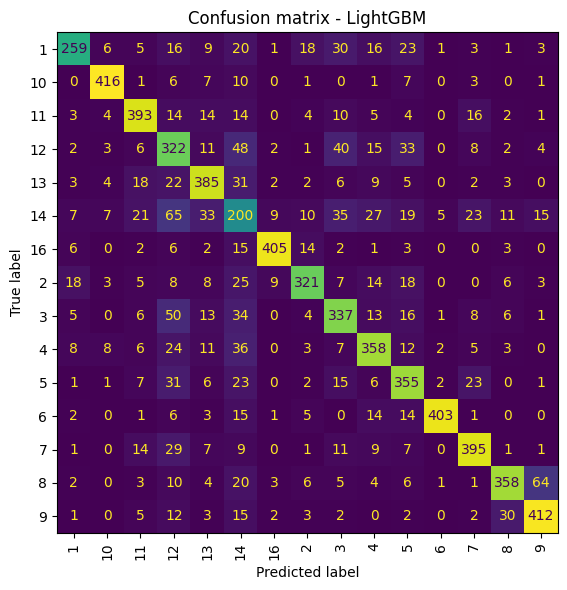

In [8]:
BEST_MODEL_NAME = results_df.iloc[0]["Model"]
# If you like, pick a specific model, for example: BEST_MODEL_NAME = "Logistic Regression"

best_pred = predictions[BEST_MODEL_NAME]
labels = np.array(sorted(pd.unique(y_test)))
cm = confusion_matrix(y_test, best_pred, labels=labels)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)
cm_df.to_csv("confusion_matrix_full.csv", encoding="utf-8-sig")
print("Confusion matrix for:", BEST_MODEL_NAME)

if len(labels) <= MAX_CLASSES_IN_PLOT:
    fig, ax = plt.subplots(figsize=(max(8, len(labels) * 0.45), max(6, len(labels) * 0.4)))
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(
        ax=ax, xticks_rotation=90, colorbar=False, values_format="d"
    )
    plt.title(f"Confusion matrix - {BEST_MODEL_NAME}")
    plt.tight_layout()
    plt.show()
else:
    top_labels = pd.Series(y_test).value_counts().head(MAX_CLASSES_IN_PLOT).index.tolist()
    display_labels = top_labels + ["Other"]
    true_grouped = np.array([x if x in top_labels else "Other" for x in y_test], dtype=object)
    pred_grouped = np.array([x if x in top_labels else "Other" for x in best_pred], dtype=object)
    cm_top = confusion_matrix(true_grouped, pred_grouped, labels=display_labels)
    fig, ax = plt.subplots(figsize=(14, 12))
    ConfusionMatrixDisplay(confusion_matrix=cm_top, display_labels=display_labels).plot(
        ax=ax, xticks_rotation=90, colorbar=False, values_format="d"
    )
    plt.title(f"Confusion matrix - {BEST_MODEL_NAME} (top classes + Other)")
    plt.tight_layout()
    plt.show()

## 9. Comparing F1 and ROC-AUC

ROC-AUC cannot always be computed for every model/split; such values stay missing. When choosing a model, look not only at a single metric but also at the quality on rare classes in `classification_report`.

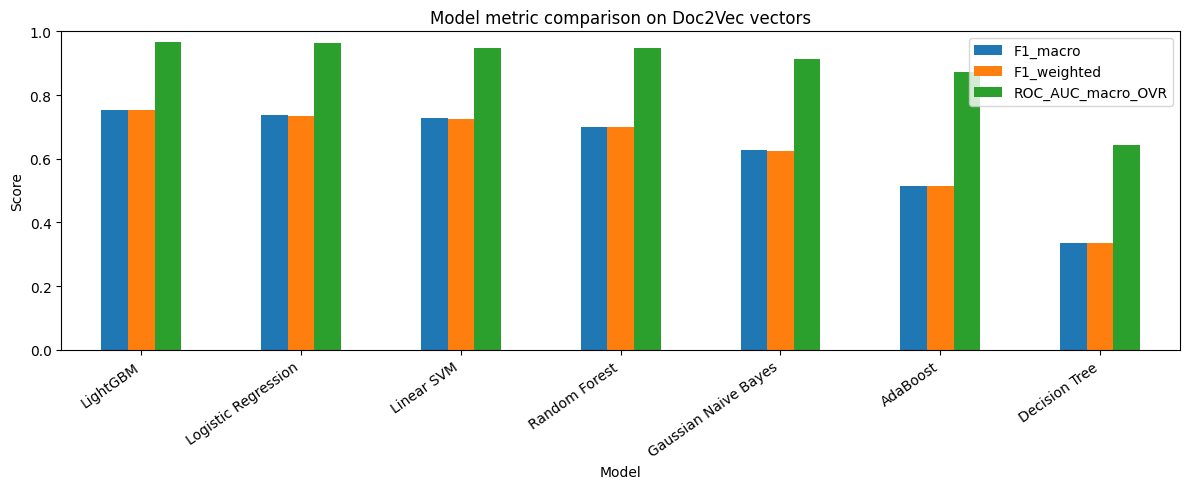

In [9]:
plot_df = results_df.set_index("Model")[["F1_macro", "F1_weighted", "ROC_AUC_macro_OVR"]]
plot_df.plot(kind="bar", figsize=(12, 5))
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.title("Model metric comparison on Doc2Vec vectors")
plt.tight_layout()
plt.show()

## 10. What to keep in mind when interpreting the results

- **ROC-AUC** evaluates how well the model ranks classes by its scores, but it does not replace F1 and error analysis.
- For a multiclass problem we use macro One-vs-Rest ROC-AUC; with rare classes, or when a class is missing from the test set, the metric may not be computable.
- For a large number of classes the confusion matrix plot is aggregated, but the full CSV is saved.
- All models in this notebook are compared on Doc2Vec vectors. To find out whether Doc2Vec is better, compare separately against TF-IDF + Linear SVM on the same train/test split.
- Train vectors are learned during Doc2Vec training, while test vectors come from `infer_vector`; this slight mismatch is normal for Doc2Vec but can lower test scores a little. Re-inferring the train vectors with `infer_vector` as well would make both sets consistent (at the cost of time).
- Linear models use standardized vectors; if you compare with the original unscaled results, small differences are expected.
- If `INFER_THREADS` is greater than 1, test vectors can differ slightly between runs; set it to 1 for exactly reproducible vectors. Doc2Vec training with several workers is also not bit-for-bit reproducible.
- If documents from the same case are similar to each other, a random split can inflate the metrics. If a case identifier is available, it is better to split train/test by case.
- The saved `model.doc2vec` is only the vectorizer. For a full deployment you also need to save the best classifier (and the scaler, if used) and the exact preprocessing settings.